In [120]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
np.random.seed(42)

X, y = make_blobs(n_samples=200, centers= 4, n_features=2, random_state=42)
print(X[:,0].min(), X[:,0].max())
print(X[:,1].min(), X[:,1].max())
# -10.962223480945816 6.526064737438632
# -8.832197392798449 10.86656431270726
noise = np.random.uniform(30, 40, size=(20, 2))
X_full = np.concatenate([X, noise])

-10.962223480945816 6.526064737438632
-8.832197392798449 10.86656431270726


In [ ]:
min_samples = 5

k = min_samples

nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_full)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [ ]:
distanze = nn.kneighbors(X_full)[0]
distanze_k = distanze[:, k-1]
distanze_k_ordinate = np.sort(distanze_k)

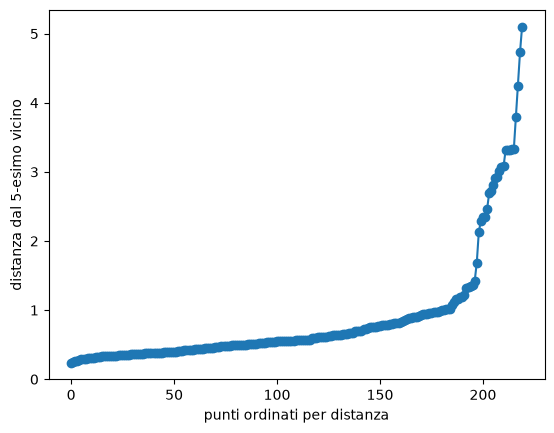

In [124]:
plt.plot(distanze_k_ordinate, marker='o')
plt.xlabel('punti ordinati per distanza')
plt.ylabel(f'distanza dal {k}-esimo vicino')
plt.show()

In [125]:
risultati = {}
eps_values = [1.2, 3.87]
for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels = dbscan.fit_predict(X_full)
    risultati[eps] = labels

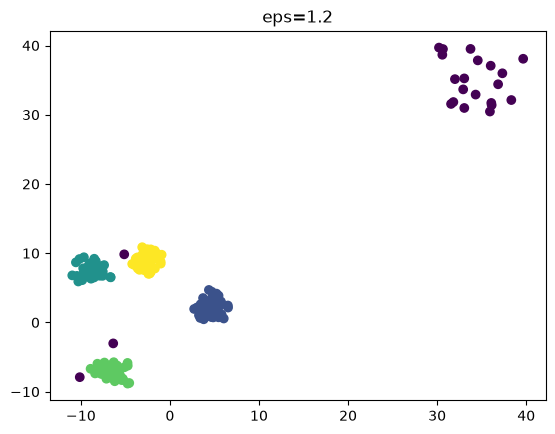

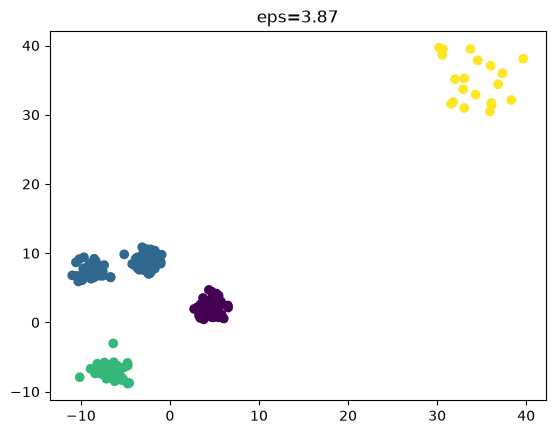

In [126]:
plt.scatter(X_full[:,0], X_full[:,1], c=risultati[1.2], cmap='viridis')
plt.title('eps=1.2')
plt.show()

plt.scatter(X_full[:,0], X_full[:,1], c=risultati[3.87], cmap='viridis')
plt.title('eps=3.87')
plt.show()

In [128]:
labels_eps12 = risultati[1.2]
outlier_veri = (labels_eps12[:200] == -1).sum()
outlier_rumore = (labels_eps12[200:] == -1).sum()
print(outlier_veri, outlier_rumore)

3 20
